# Práctica 1 — Herramientas básicas

En esta práctica se repasan las librerías que usaremos durante la asignatura:

| # | Apartado | Librería |
|---|----------|----------|
| 1 | Importaciones | — |
| 2 | Álgebra matricial | `numpy` |
| 3 | Distribuciones de probabilidad | `scipy.stats` |
| 4 | Gráficas | `matplotlib` |
| 5 | Aprendizaje automático | `scikit-learn` |
| 6 | Conjuntos de datos | `datasets` (Hugging Face) |

## 1. Importaciones

In [2]:
import numpy as np
from scipy import stats

---
## 2. NumPy

**Ejercicio:** traduce a NumPy el siguiente pseudo-script:

```text
import numpy as np
X       = matriz [-1, 1; 0, 2; 2, 0; 3, 3]
N       = número de filas de X
mean    = media de los datos
X_tilde = X - media
Sigma   = matriz de covarianzas empírica calculada a partir de X_tilde
```

In [ ]:
print('EJERCICIO 2')

### 2.1 Matriz de datos

```text
X = matriz [-1, 1; 0, 2; 2, 0; 3, 3]
```

Cada fila es un dato y cada columna una característica.

In [ ]:
X = np.array([ [-1, -1], [0, 2], [2, 0], [3, 3] ])
print(X, '\n')

### 2.2 Número de filas

```text
N = número de filas de X
```

Se comprueba que `len(X)` y `X.shape[0]` dan lo mismo.

In [ ]:
N = len(X)
print(N, X.shape[0], '\n')

### 2.3 Media

```text
mean = media de los datos
```

Media por columnas (`axis=0`): $\bar{x} = \frac{1}{N}\sum_{n=1}^{N} x_n$

In [ ]:
mean = X.mean(axis=0)
print(mean, '\n')

### 2.4 Datos centrados

```text
X_tilde = X - media
```

$\tilde{X} = X - \bar{x}$ (NumPy hace *broadcasting* de la media a todas las filas).

In [ ]:
X_tilde = X - mean
print(X_tilde, '\n')

### 2.5 Matriz de covarianzas

```text
Sigma = matriz de covarianzas empírica calculada a partir de X_tilde
```

$$
\Sigma = \frac{1}{N}\, \tilde{X}^\top \tilde{X}
$$

In [ ]:
Sigma = (1 / N) * X_tilde.T @ X_tilde
print(Sigma)

---
## 3. SciPy

**Ejercicio:** traduce a SciPy el siguiente pseudo-script:

```text
from scipy import stats
Y   = array 1d con 10 muestras de una Bernoulli con probabilidad 0.25 de 1
Y   = array 2d con 3 muestras de una categórica para 3 clases con probabilidades (0.3, 0.2, 0.5)
Y   = array 1d con 5 muestras de una normal 1d estándar
Y   = rejilla 1d de 5 puntos en [-1, 1]
pdf = array 1d con la pdf de una normal 1d estándar en Y
Y   = rejilla 2d de 3**2 puntos en [-1, 1]**2
pdf = array 2d con la pdf de una normal 2d estándar en Y
```

In [ ]:
print('EJERCICIO 3')

### 3.1 Bernoulli

```text
Y = array 1d con 10 muestras de una Bernoulli con probabilidad 0.25 de 1
```

$Y \sim \text{Bernoulli}(0.25)$, es decir, $P(Y=1) = 0.25$.

In [ ]:
t = 0.25 
Y = stats.bernoulli(t)
print(Y.rvs(10), '\n')

### 3.2 Categórica

```text
Y = array 2d con 3 muestras de una categórica para 3 clases con probabilidades (0.3, 0.2, 0.5)
```

Se modela como una multinomial con un único ensayo (`n = 1`), por lo que cada muestra es un vector *one-hot*.

In [ ]:
t = [0.3, 0.2, 0.5]
Y = stats.multinomial(1, t)
print(Y.p, str(Y.rvs(5)), '\n')

### 3.3 Muestras de una normal 1d

```text
Y = array 1d con 5 muestras de una normal 1d estándar
```

$Y \sim \mathcal{N}(0, 1)$

In [ ]:
Y = stats.norm(0,1)
print(Y.rvs(5), '\n')

### 3.4 Rejilla 1d

```text
Y = rejilla 1d de 5 puntos en [-1, 1]
```

In [ ]:
Y = np.linspace(-1, 1, 5)
print(Y, '\n')

### 3.5 pdf de una normal 1d

```text
pdf = array 1d con la pdf de una normal 1d estándar en Y
```

$$
p(y) = \frac{1}{\sqrt{2\pi}}\, e^{-y^2/2}
$$

In [ ]:
pdf = stats.norm(0, 1).pdf(Y)
print(pdf, '\n')

### 3.6 Normal 2d estándar *(extra)*

No se pide en el pseudo-script, pero define la media `m` y la covarianza `S` que se usan en el apartado 3.8: $\mathcal{N}(\mathbf{0}, I)$.

In [ ]:
m = np.zeros(2)
S = np.eye(2)
Y = stats.multivariate_normal(m, S)
print(Y.rvs(3), '\n')

### 3.7 Rejilla 2d

```text
Y = rejilla 2d de 3**2 puntos en [-1, 1]**2
```

Se crea la rejilla con `meshgrid` y se aplana en una matriz de $9 \times 2$ (un punto por fila).

In [ ]:
Y = np.linspace(-1, 1, 3)
Y1, Y2 = np.meshgrid(Y, Y)
Y = np.c_[np.ravel(Y1), np.ravel(Y2)]
print(Y)

### 3.8 pdf de una normal 2d

```text
pdf = array 2d con la pdf de una normal 2d estándar en Y
```

In [ ]:
pdf = stats.multivariate_normal(m, S).pdf(Y)
print(pdf)

---
## 4. Matplotlib

**Ejercicio:** estudia el código del siguiente script y prueba valores de $\mathbf{a} \in \{-1, 1\}^2$.

El script representa la función cuadrática

$$
y = a_1 x_1^2 + a_2 x_2^2
$$

- **Izquierda:** curvas de nivel y el gradiente negativo $-\nabla y = -(2a_1 x_1,\ 2a_2 x_2)$ (dirección de máximo descenso).
- **Derecha:** superficie 3d en *wireframe*; el `*` marca el punto crítico $(0, 0)$.

Según los signos de $\mathbf{a}$ el origen es un **mínimo** $(1, 1)$, un **máximo** $(-1, -1)$ o un **punto de silla** $(1, -1)$ / $(-1, 1)$.

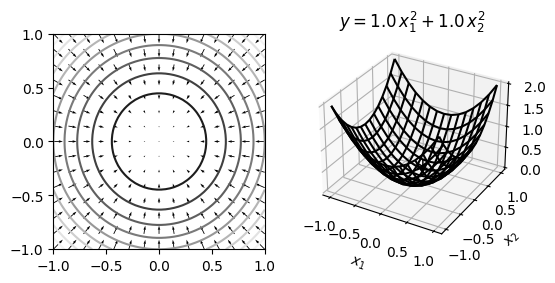

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Rejilla fina para las curvas de nivel
R = np.linspace(-1, 1, 50)
X1, X2 = np.meshgrid(R, R)
X = np.c_[np.ravel(X1), np.ravel(X2)]

# Coeficientes de la función y = a1·x1² + a2·x2²
a = np.array([1, 1])
Y = (np.square(X) @ a).reshape(X1.shape)

# Gráfica izquierda: curvas de nivel
fig = plt.figure(figsize=(6, 2.8))
ax = plt.subplot(121)
ax.contour(X1, X2, Y, 10, cmap='Greys_r')

# Rejilla gruesa para dibujar el gradiente negativo
r = np.linspace(-1, 1, 15)
x1, x2 = np.meshgrid(r, r)
x = np.c_[np.ravel(x1), np.ravel(x2)]
neg_grad = -x @ np.diag(2*a)
ax.quiver(x[:,0], x[:,1], neg_grad[:,0], neg_grad[:,1], color='black', angles='xy')

# Gráfica derecha: superficie 3d
ax = plt.subplot(122, projection='3d')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title(f'$y={a[0]:.1f}\\,x_1^2{a[1]:+.1f}\\,x_2^2$')
ax.text(0, 0, 0, '*', fontsize=20)
ax.plot_wireframe(x1, x2, a[0]*x1**2 + a[1]*x2**2, color='black')

plt.show()

---
## 5. scikit-learn

**Ejercicio:** empieza con el [Getting Started](https://scikit-learn.org/stable/getting_started.html) si es la primera vez que usas scikit-learn.

In [ ]:
pass

---
## 6. Datasets

**Ejercicio:** comprueba que puedes leer **MNIST**, **Fashion-MNIST** y **CIFAR-10**.

Se cargan desde el Hub de Hugging Face con formato `numpy`.

### 6.1 MNIST

Dígitos manuscritos (0–9) en escala de grises, 28×28 píxeles.

In [22]:
import numpy as np; import datasets
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy"); ds

/home/serafim/Desktop/vs/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

### 6.2 Fashion-MNIST

Prendas de ropa en 10 clases, escala de grises, 28×28 píxeles.

In [23]:
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy"); ds['train']

Generating test split: 100%|██████████| 10000/10000 [00:00<00:00, 609628.35 examples/s]


Dataset({
    features: ['image', 'label'],
    num_rows: 60000
})

### 6.3 CIFAR-10

Imágenes en color de 10 clases de objetos, 32×32 píxeles.

In [24]:
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy"); ds['train']

Generating test split: 100%|██████████| 10000/10000 [00:00<00:00, 370272.96 examples/s]


Dataset({
    features: ['img', 'label'],
    num_rows: 50000
})